# Plant DDN-01 – data profiling (Part B)

This notebook walks through the data pack: what each file contains, how each one names equipment, and the
data-quality problems that make contextualization necessary. It calls the same functions as the pipeline
(`ddn.load`, `ddn.profile`, `ddn.quality`, `ddn.identity`), so its numbers match `reports/01`–`04`.

Needs the pack's data files in `data/raw/`. Run from the project root or from `notebooks/`.

In [1]:
import sys, pathlib
root = pathlib.Path.cwd() if (pathlib.Path.cwd() / "src").exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(root / "src"))

import pandas as pd
import matplotlib.pyplot as plt
from ddn.load import load_all
from ddn.profile import profile_one
from ddn import quality

pd.set_option("display.max_colwidth", 80)
data = load_all()
print(f"{len(data)} files loaded")

14 files loaded


## 1. Size, keys and time coverage of every file

In [2]:
prof = pd.DataFrame([profile_one(n, df) for n, df in data.items()])
prof[["file", "rows", "cols", "key", "key_unique", "dup_keys", "coverage", "how"]]

,file,rows,cols,key,key_unique,dup_keys,coverage,how
0,assets_cmms_export.csv,455,10,functional_location,True,0,—,Canonical ISA-95 path `DDN1-<shop>-<line>-<stn>-<equip>-<comp>` + SAP equipm...
1,historian_tag_list.csv,1541,6,tag_name,True,0,—,"Equipment is embedded in the tag name, in 4 conventions (PI, WinCC, S7, MES)"
2,timeseries_1min.csv.gz,1101823,4,tag_name + timestamp,True,0,2026-09-01 00:00 → 2026-09-14 23:59,Only via tag_name -> historian tag list -> asset (no direct asset id)
3,vehicles.csv,7200,5,vin,True,0,2026-09-01 00:00 → 2026-09-14 23:57,"None - a vehicle is a product, not equipment"
4,mes_vehicle_passages.csv.gz,310462,4,vin + mes_station,True,0,2026-09-01 00:00 → 2026-09-15 11:55,MES station code (B2-04) and RFID reader (RD-B2-04); not functional locations
5,mes_station_master.csv,46,3,mes_station,True,0,—,MES station codes; no link to SAP - must be built
6,torque_results.csv.gz,79855,12,result_id,True,0,2026-09-01 07:32 → 2026-09-15 10:55,Tool controller channel TCnn (= nutrunner NRnn) or hand wrench HW-07
7,part_lot_genealogy.csv.gz,64800,7,vin + part_no,True,0,2026-09-01 00:20 → 2026-09-15 10:55,Only the MES station where the part was fitted
8,press_panel_batches.csv,104,6,batch_id,True,0,2026-08-31 00:00 → 2026-09-14 18:00,Press line code (PL1/PL2) and die id (D-BSO-LH-03)
9,quality_defects.csv,675,9,defect_id,True,0,2026-09-01 04:13 → 2026-09-15 09:07,Inspection point (MES code) only - never the equipment that caused it


## 2. How each file identifies equipment

The same robot is `DDN1-BIW-L2-ST04-RB07` in SAP, `DDN1_BIW_L2_R07_WELDCUR.PV` in the historian, `R7` in a work
order and `B2-04` in MES. Below: the column each file uses and three real values.

In [3]:
pd.DataFrame([{"file": p["file"], "equipment columns": ", ".join(p["equip_cols"]),
               "examples": "; ".join(str(v) for vals in p["examples"].values() for v in vals)}
              for p in prof.to_dict("records")])

,file,equipment columns,examples
0,assets_cmms_export.csv,"functional_location, cmms_equipment_no, name",DDN1; DDN1-PRS; DDN1-BIW; 10006202; 10002992; 10004453; Plant DDN-01; Press ...
1,historian_tag_list.csv,"tag_name, description",PRS.PL1.DST.SPD; PRS.PL1.DST.CUR; PRS.PL1.DST.STATUS; Destacker PL1 Speed; D...
2,timeseries_1min.csv.gz,tag_name,DDN1_BIW_L2_R01_WELDCUR.PV; DDN1_BIW_L2_R02_WELDCUR.PV; DDN1_BIW_L2_R03_WELD...
3,vehicles.csv,,
4,mes_vehicle_passages.csv.gz,"mes_station, reader_id",B1-01; B1-02; B1-03; RD-B1-01; RD-B1-02; RD-B1-03
5,mes_station_master.csv,"mes_station, description",B1-01; B1-02; B1-03; Underbody stn 1; Underbody stn 2; Underbody stn 3
6,torque_results.csv.gz,tool_id,TC08; TC09; TC10
7,part_lot_genealogy.csv.gz,fitted_mes_station,T2-01; T1-01; F1-04
8,press_panel_batches.csv,"press_line, die_id",PL1; PL2; D-BSO-LH-03; D-ROOF-01
9,quality_defects.csv,inspection_point,BIQ-1; EOL-WT; EOL-AUD


## 3. Historian tags: four naming conventions

source_system
MES                         FA_TR1_CV01_SPD
PI Historian        DDN1_BIW_L1_CV01_SPD.PV
S7 legacy OPC               PRS.PL1.DST.SPD
WinCC SCADA      PaintShop-EDOven-Z1-Tempsp
Name: tag_name, dtype: str

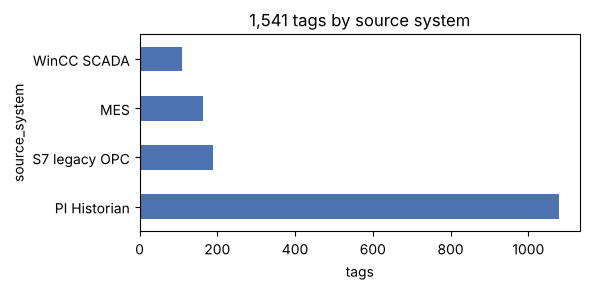

In [4]:
tags = data["historian_tag_list.csv"]
fig, ax = plt.subplots(figsize=(6, 3))
tags.source_system.value_counts().plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel("tags"); ax.set_title("1,541 tags by source system"); plt.tight_layout()
tags.groupby("source_system").tag_name.first()

## 4. Time series: gaps, an outage, a stuck sensor, °C and °F

In [5]:
ts = data["timeseries_1min.csv.gz"]
print(ts.shape, ts.columns.tolist())
units = tags.set_index("tag_name").engineering_unit
per_tag = ts.groupby("tag_name").agg(rows=("value", "size"), start=("timestamp", "min"), end=("timestamp", "max"),
                               std=("value", "std"))
per_tag["unit"] = per_tag.index.map(units)
per_tag.sort_values("rows").head(8)

(1101823, 4) ['timestamp', 'tag_name', 'value', 'quality']


,rows,start,end,std,unit
tag_name,,,,,
DDN1_BIW_L1ST3_RB5_WELDCUR.PV,20011,2026-09-01,2026-09-14 23:59:00,3.441436,kA
DDN1_PNT_PT_T102_TEMP.PV,20011,2026-09-01,2026-09-14 23:59:00,3.528571,degC
PaintShop-AirHandling-AHUTC2-Rh,20012,2026-09-01,2026-09-14 23:59:00,1.901984,%RH
DDN1_PNT_SL_SR04_NOZTEMP.PV,20013,2026-09-01,2026-09-14 23:59:00,7.011907,degC
DDN1_BIW_L2_R04_WELDCUR.PV,20014,2026-09-01,2026-09-14 23:59:00,3.424506,kA
PRS.PL2.PR1.SPM,20016,2026-09-01,2026-09-14 23:59:00,4.219360,spm
DDN1_BIW_L2_R08_WELDCUR.PV,20019,2026-09-01,2026-09-14 23:59:00,3.396576,kA
DDN1_PNT_SL_SR06_FLOW.PV,20019,2026-09-01,2026-09-14 23:59:00,42.105770,NaN


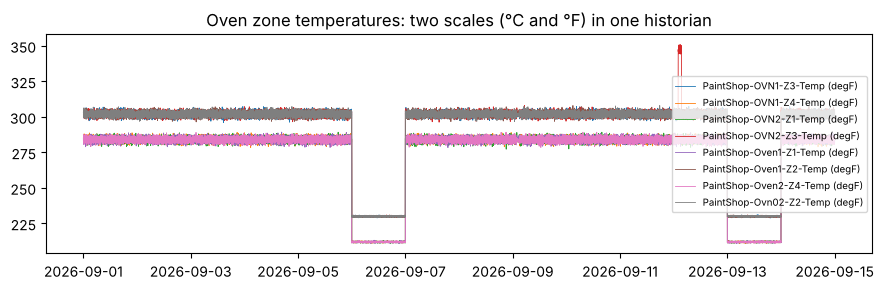

In [6]:
fig, ax = plt.subplots(figsize=(9, 3))
oven = ts[ts.tag_name.str.contains("OV|Ov", regex=True) & ts.tag_name.str.contains("Temp")]
for tag, g in oven.groupby("tag_name"):
    ax.plot(g.timestamp, g.value, lw=0.6, label=f"{tag} ({units.get(tag, '?')})")
ax.set_title("Oven zone temperatures: two scales (°C and °F) in one historian"); ax.legend(fontsize=7)
plt.tight_layout()

## 5. Quality defects: logged against VIN and inspection point, never against equipment

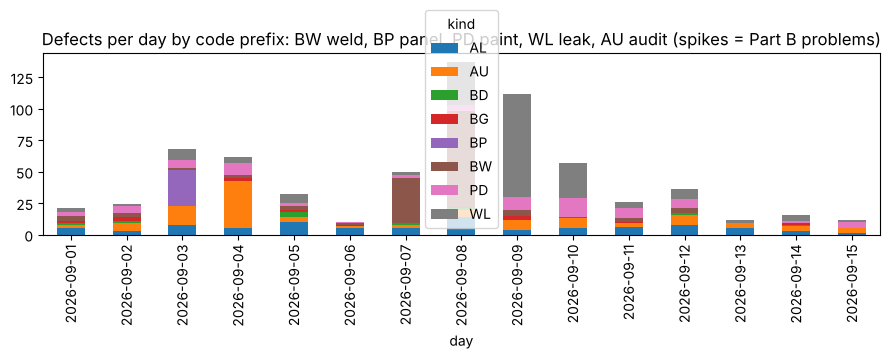

In [7]:
d = data["quality_defects.csv"]
daily = d.assign(day=d.detected_at.dt.date, kind=d.defect_code.str[:2]).pivot_table(index="day", columns="kind",
                                                          values="defect_id", aggfunc="count", fill_value=0)
daily.plot.bar(stacked=True, figsize=(9, 3.5), title="Defects per day by code prefix: BW weld, BP panel, PD paint, WL leak, AU audit (spikes = Part B problems)")
plt.tight_layout()

## 6. Data-quality issues

The full list with evidence is `reports/02_data_quality.md`; here the summary by dataset and severity.
`documented` = already mentioned in the data dictionary.

In [8]:
issues = pd.DataFrame([i.model_dump() for i in quality.run_all()])
print(f"{len(issues)} issues, {(~issues.documented).sum()} not in the data dictionary")
issues.pivot_table(index="dataset", columns="severity", values="check", aggfunc="count", fill_value=0)

38 issues, 15 not in the data dictionary


severity,High,Low,Medium
dataset,,,
alarms,1,0,3
assets,3,0,2
mes_station_master,0,1,0
mes_vehicle_passages,2,0,0
part_lot_genealogy,1,0,0
quality_defects,1,1,1
tags,3,0,3
timeseries,2,3,0
torque_results,1,2,0


In [9]:
issues[["dataset", "check", "severity", "count", "documented"]].sort_values(["severity", "dataset"])

,dataset,check,severity,count,documented
34,alarms,Mixed separators in source path (count = distinct sources),High,272,True
0,assets,Missing parent functional location,High,18,True
3,assets,Same name on different assets,High,18,True
4,assets,Relocated equipment,High,1,False
18,mes_vehicle_passages,Missing RFID reads,High,6069,True
19,mes_vehicle_passages,RFID reader offline (consecutive missed reads),High,49,True
20,part_lot_genealogy,Lot id reused far beyond a normal lot size,High,1,False
26,quality_defects,Defects never reference equipment,High,675,True
5,tags,Tag name breaks its system's naming convention (typos),High,13,True
9,tags,Temperatures in deg F (rest of plant deg C),High,24,True


## 7. What this means for Parts C–E

* No shared key across systems → entity matching (Part C) is required, not optional.
* Units differ per source → normalise before comparing values (staging converts °F to °C).
* Defects never name equipment → the only way from a defect to a machine is VIN → station → time window →
  equipment, i.e. the graph (Part D).
* The defect spikes in section 5 are the production problems listed in `reports/04_production_problems.md`;
  Part E1 must find them in the signals.